# Puste i przepełnione stacje – koncentracja (hipoteza H2)

**H2:** brak rowerów nie rozkłada się równomiernie – niewielka część stacji odpowiada za większość czasu, w którym stacje są puste.

Dane: `processed/observed_timeseries.parquet` (stan stacji co 5 min, tylko stacje aktywne) i `processed/stations.parquet`. Najpierw uruchom `python -m src.data.build`.

- **pusta** – `bikes == 0` (nie da się wypożyczyć),
- **przepełniona** – `bikes > capacity`; na stacjach Veturilo 3.0 to dozwolone (rowery można zostawiać ponad stojaki), więc to sygnał nadmiaru, a nie blokady zwrotów.

Miara koncentracji: krzywa Lorenza i współczynnik Giniego udziału czasu „pusta” po stacjach (0 = równomiernie, 1 = cały czas pustek na jednej stacji).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "processed").exists() else Path.cwd().parent
P = ROOT / "processed"
obs = pd.read_parquet(P / "observed_timeseries.parquet")
stations = pd.read_parquet(P / "stations.parquet")

# Paleta (dataviz: kolejność kategorii stała, tekst w kolorach tekstu)
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "axes.titlecolor": INK, "axes.titlesize": 12, "axes.titleweight": "bold",
    "font.size": 10, "legend.frameon": False, "lines.linewidth": 2,
})
print(f"{len(obs):,} rekordów, {obs['station_id'].nunique()} stacji, "
      f"{obs['time'].min():%Y-%m-%d %H:%M} – {obs['time'].max():%Y-%m-%d %H:%M} UTC")

351,234 rekordów, 342 stacji, 2026-10-22 13:08 – 2026-10-26 08:20 UTC


## Udział czasu pustej i przepełnionej stacji

In [2]:
per = (obs.groupby("station_id")
         .agg(share_empty=("is_empty", "mean"), share_overfull=("is_overfull", "mean"), n=("is_empty", "size"))
         .join(stations.set_index("station_id")[["name", "capacity", "lat", "lon"]]))
print(f"Stacje kiedykolwiek puste: {(per.share_empty > 0).mean():.0%}; "
      f"puste > 10% czasu: {(per.share_empty > 0.10).sum()}; "
      f"przepełnione > 50% czasu: {(per.share_overfull > 0.5).sum()}")
cols = ["name", "capacity", "share_empty", "share_overfull"]
display(per.sort_values("share_empty", ascending=False)[cols].head(15)
        .style.format({"share_empty": "{:.1%}", "share_overfull": "{:.1%}"}).set_caption("Najczęściej puste"))
display(per.sort_values("share_overfull", ascending=False)[cols].head(15)
        .style.format({"share_empty": "{:.1%}", "share_overfull": "{:.1%}"}).set_caption("Najczęściej przepełnione"))

Stacje kiedykolwiek puste: 51%; puste > 10% czasu: 9; przepełnione > 50% czasu: 119


,name,capacity,share_empty,share_overfull
station_id,,,,
2585425,Metro Nowy Świat - Uniwersytet,14,19.6%,3.9%
2585684,Rondo de Gaulle'a,10,17.5%,8.7%
2585720,al. Niepodległości - Nowowiejska,14,17.2%,0.0%
2585766,Marszałkowska - Litewska,8,16.0%,1.2%
2585416,Marszałkowska - Królewska,10,13.7%,41.0%
2585838,Metro Wilanowska - Dworzec Południowy,12,12.2%,0.0%
2585346,Metro Księcia Janusza,10,11.9%,0.2%
2585335,al. Jana Pawła II - Anielewicza,14,11.3%,0.0%
2585913,Metro Kabaty,12,10.3%,26.5%


,name,capacity,share_empty,share_overfull
station_id,,,,
2586031,Metro Szwedzka,9,0.0%,100.0%
2586014,Wybrzeże Szczecińskie - Stadion Narodowy,16,0.0%,100.0%
2585278,OSiR Żoliborz,8,0.0%,100.0%
2585863,Vogla - Syta,8,0.0%,100.0%
2585868,al. Rzeczypospolitej - Klimczaka,8,0.0%,100.0%
2585911,Ordonówny - Światowida,10,0.0%,100.0%
2585431,Centrum Nauki Kopernik,16,0.0%,100.0%
2585921,Grupy AK Krybar,8,0.0%,100.0%
2585974,Park Kępa Potocka,10,0.0%,100.0%


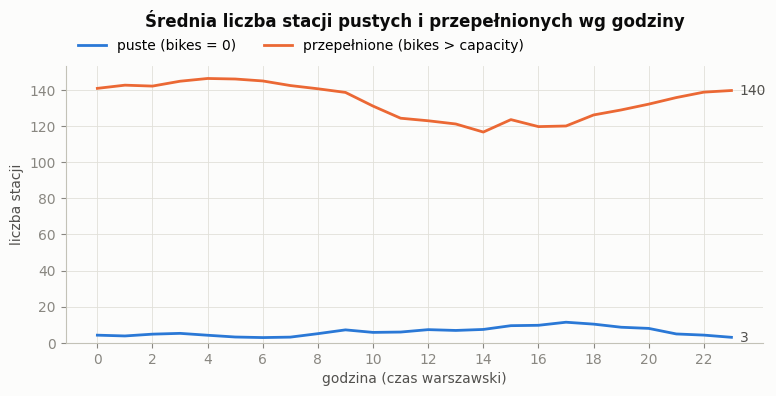

In [3]:
obs["hour"] = obs["time"].dt.tz_convert("Europe/Warsaw").dt.hour
snap = obs.groupby("time").agg(empty=("is_empty", "sum"), overfull=("is_overfull", "sum"))
snap["hour"] = snap.index.tz_convert("Europe/Warsaw").hour
prof = snap.groupby("hour")[["empty", "overfull"]].mean()

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(prof.index, prof["empty"], color=BLUE, label="puste (bikes = 0)")
ax.plot(prof.index, prof["overfull"], color=ORANGE, label="przepełnione (bikes > capacity)")
for col, c in [("empty", BLUE), ("overfull", ORANGE)]:
    ax.annotate(f"{prof[col].iloc[-1]:.0f}", (prof.index[-1], prof[col].iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", color=INK2)
ax.set(xlabel="godzina (czas warszawski)", ylabel="liczba stacji", xticks=range(0, 24, 2), ylim=(0, None))
ax.set_title("Średnia liczba stacji pustych i przepełnionych wg godziny", pad=28)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
plt.show()

## Krzywa Lorenza i współczynnik Giniego (H2)

Stacje posortowane rosnąco wg udziału czasu, w którym były puste. Oś X – skumulowany odsetek stacji, oś Y – skumulowany odsetek łącznego czasu pustek. Im dalej krzywa od przekątnej, tym silniejsza koncentracja. Dla porównania ta sama miara dla przepełnienia.

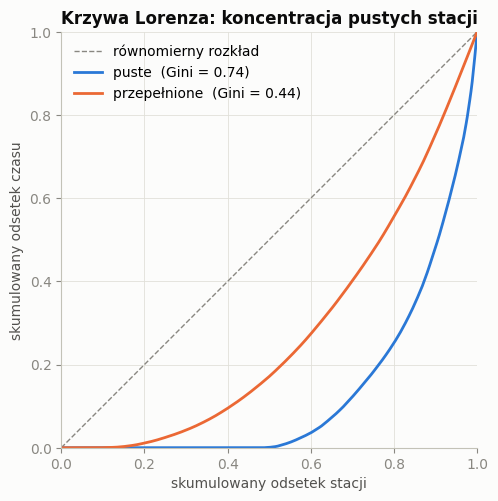

Gini (puste):        0.738
Gini (przepełnione): 0.443
10% najczęściej pustych stacji = 52% czasu pustek; 20% = 75%; nigdy pustych: 49% stacji


In [4]:
def lorenz(values):
    v = np.sort(np.asarray(values, float))
    cum = np.concatenate([[0], np.cumsum(v)]) / v.sum()
    x = np.linspace(0, 1, len(v) + 1)
    return x, cum

def gini(values):
    x, y = lorenz(values)
    return 1 - 2 * np.trapezoid(y, x)

def top_share(values, frac):
    v = np.sort(np.asarray(values, float))[::-1]
    return v[: max(1, int(round(frac * len(v))))].sum() / v.sum()

g_empty, g_over = gini(per.share_empty), gini(per.share_overfull)

fig, ax = plt.subplots(figsize=(5.4, 5.4))
ax.plot([0, 1], [0, 1], color=MUTED, lw=1, ls="--", label="równomierny rozkład")
for col, c, g, lab in [("share_empty", BLUE, g_empty, "puste"), ("share_overfull", ORANGE, g_over, "przepełnione")]:
    x, y = lorenz(per[col])
    ax.plot(x, y, color=c, label=f"{lab}  (Gini = {g:.2f})")
ax.set(title="Krzywa Lorenza: koncentracja pustych stacji", xlabel="skumulowany odsetek stacji",
       ylabel="skumulowany odsetek czasu", xlim=(0, 1), ylim=(0, 1))
ax.set_aspect("equal")
ax.legend(loc="upper left")
plt.show()

print(f"Gini (puste):        {g_empty:.3f}")
print(f"Gini (przepełnione): {g_over:.3f}")
print(f"10% najczęściej pustych stacji = {top_share(per.share_empty, 0.10):.0%} czasu pustek; "
      f"20% = {top_share(per.share_empty, 0.20):.0%}; nigdy pustych: {(per.share_empty == 0).mean():.0%} stacji")

### Stabilność wyniku

Gini z kilku dni może zależeć od konkretnych dni. Liczymy go (1) osobno dla każdego dnia i (2) z pominięciem po kolei każdego dnia (leave-one-day-out). Klasyczny bootstrap po dniach ma sens dopiero przy ok. 2 tygodniach danych – przy 3–4 dniach jest obciążony w górę (powtórzone dni sztucznie zwiększają koncentrację).

In [5]:
obs["day"] = obs["time"].dt.tz_convert("Europe/Warsaw").dt.date
daily = obs.groupby(["day", "station_id"])["is_empty"].agg(["sum", "size"]).reset_index()
days = sorted(daily["day"].unique())
rows = []
for d in days:
    one = daily[daily["day"] == d]
    rest = daily[daily["day"] != d].groupby("station_id")[["sum", "size"]].sum()
    rows.append({"dzień": d, "pomiary": int(one["size"].max()),
                 "Gini tego dnia": gini(one["sum"] / one["size"]),
                 "Gini bez tego dnia": gini(rest["sum"] / rest["size"])})
stab = pd.DataFrame(rows)
display(stab.style.format({"Gini tego dnia": "{:.3f}", "Gini bez tego dnia": "{:.3f}"}).hide(axis="index"))
print(f"Gini (puste) = {g_empty:.3f}; leave-one-day-out: "
      f"{stab['Gini bez tego dnia'].min():.3f} – {stab['Gini bez tego dnia'].max():.3f}")

dzień,pomiary,Gini tego dnia,Gini bez tego dnia
2026-10-22,38,0.935,0.742
2026-10-23,288,0.806,0.799
2026-10-24,288,0.872,0.750
2026-10-25,300,0.891,0.758
2026-10-26,113,0.970,0.744


Gini (puste) = 0.738; leave-one-day-out: 0.742 – 0.799


## Gdzie są stacje często puste

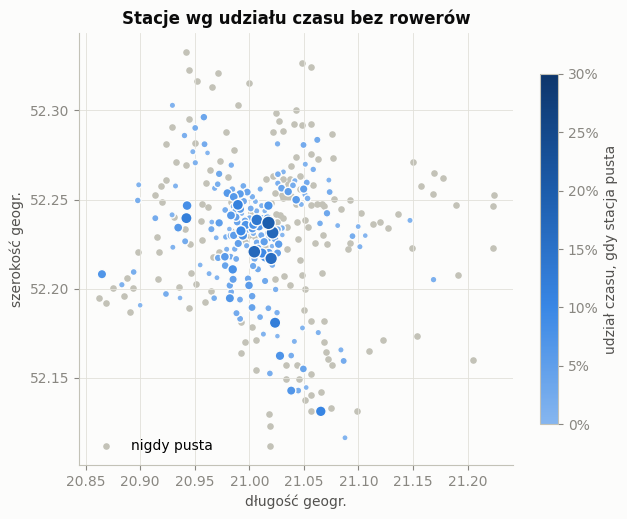

In [6]:
fig, ax = plt.subplots(figsize=(7, 6.5))
never = per[per.share_empty == 0]
ever = per[per.share_empty > 0].sort_values("share_empty")
ax.scatter(never.lon, never.lat, s=14, color=AXIS, label="nigdy pusta", zorder=1)
from matplotlib.colors import LinearSegmentedColormap
# skala sekwencyjna jednego odcienia; start od kroku 250, zeby male wartosci byly widoczne na jasnym tle
seq = LinearSegmentedColormap.from_list("blue_seq", ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
sc = ax.scatter(ever.lon, ever.lat, s=18 + 400 * ever.share_empty, c=ever.share_empty, cmap=seq,
                vmin=0, vmax=max(0.3, ever.share_empty.max()), edgecolor=SURFACE, linewidth=1, zorder=2)
cb = fig.colorbar(sc, ax=ax, shrink=0.7, format=lambda v, _: f"{v:.0%}")
cb.set_label("udział czasu, gdy stacja pusta", color=INK2)
ax.set(title="Stacje wg udziału czasu bez rowerów", xlabel="długość geogr.", ylabel="szerokość geogr.")
ax.set_aspect(1 / np.cos(np.radians(52.23)))
ax.legend(loc="lower left")
plt.show()

## Wnioski (uzupełniane przy każdym przeliczeniu)

- Gini i udział 10%/20% najczęściej pustych stacji (komórka z krzywą Lorenza) to bezpośredni test H2: wysoki Gini (np. > 0,6) oznacza silną koncentrację pustek.
- Przy kilku dniach danych wynik jest wstępny (patrz tabela stabilności) – wniosek o H2 formułować po zebraniu ≥ 2 tygodni, wtedy też z bootstrapem po dniach.
- Przepełnienie nie blokuje zwrotów (pojemność „miękka”), więc w modelu stacje przepełnione nie odrzucają klientów, a stacje puste – tak (utracony popyt).